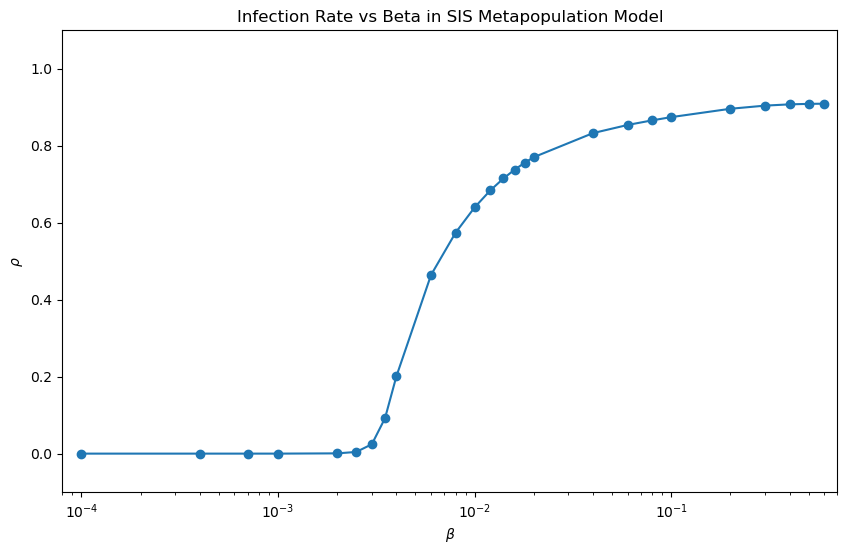

In [3]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import random

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

# 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
def generate_small_world_network(N, k, p_rewire):
    G = nx.watts_strogatz_graph(N, k, p_rewire)
    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(1, 10)
    W = nx.to_numpy_array(G, weight='weight')
    return W

# 计算C矩阵
def calculate_C_matrix(W):
    N = W.shape[0]
    C = np.zeros_like(W, dtype=float)
    for i in range(N):
        row_sum = np.sum(W[i, :])
        if row_sum > 0:
            C[i, :] = W[i, :] / row_sum
    return C

# 生成每个子种群的网络并计算平均度
def generate_subpopulations(N):
    n = np.random.randint(50, 101, size=N)  # 每个节点的初始人口
    average_degrees = n * 0.1
    return n, average_degrees

# 运行模拟实验
def run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps):

    rho = np.full(N, initial_infected_density)
    # R_i = np.zeros(N)
    # D_i = np.zeros(N)
    # P_i = np.zeros(N)
    # Pi_i = np.zeros(N)
    for t in range(steps):
        new_rho = np.zeros(N)
        R_i = np.zeros(N)
        D_i = np.zeros(N)
        P_i = np.zeros(N)
        Pi_i = np.zeros(N)
        for i in range(N):
            R_i[i] = 1 - (1 - beta) ** ((1 - p_move) * average_degrees[i] * rho[i] +
                                     np.sum([p_move * C[j, i] * average_degrees[j] * rho[j] for j in range(N)]))
            D_i[i] = 1 - (1 - beta) ** ((1 - p_move) * n[i] * rho[i] +
                                     np.sum([p_move * C[j, i] * n[j] * rho[j] for j in range(N)]))
            P_i[i] = alpha * R_i[i] + (1 - alpha) * D_i[i]
        for i in range(N):
            Pi_i[i] = (1 - p_move) * P_i[i] + p_move * np.sum([C[i, j] * P_i[j] for j in range(N)])
            new_rho[i] = (1 - mu) * rho[i] + (1 - rho[i]) * Pi_i[i]
        rho = new_rho
    return np.mean(rho)

def run_multiple_simulations(num_simulations, beta_values, N, initial_infected_density, mu, p_move, alpha, steps):
    rho_end_values_accumulated = np.zeros(len(beta_values))
    for _ in range(num_simulations):
        W = generate_small_world_network(N, 8, 0.8) # k = 8 p_rewire = 0.8
        C = calculate_C_matrix(W)
        n, average_degrees = generate_subpopulations(N)
        rho_end_values = [run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps) for beta in beta_values]
        rho_end_values_accumulated += rho_end_values
    rho_end_values_mean = rho_end_values_accumulated / num_simulations
    return rho_end_values_mean

# 初始变量
N = 20
initial_infected_density = 0.01

mu = 0.1
p_move = 0.1
alpha = 0.6
steps = 100

# 方法四：生成不同区间的 beta 值
beta_values = np.concatenate([
    np.arange(0.0001, 0.001, 0.0003),
    np.arange(0.001, 0.002, 0.001),
    np.arange(0.002, 0.003, 0.0005),
    np.arange(0.003, 0.004, 0.0005),
    np.arange(0.004, 0.01, 0.002),
    np.arange(0.01, 0.02, 0.002),
    np.arange(0.02, 0.1, 0.02),
    np.arange(0.1, 0.7, 0.1)
])

# 运行多次模拟并计算平均感染率
num_simulations = 10
rho_end_values_mean = run_multiple_simulations(num_simulations, beta_values, N, initial_infected_density, mu, p_move, alpha, steps)

# 绘制结果
plt.figure(figsize=(10, 6))
plt.plot(beta_values, rho_end_values_mean, marker='o')
plt.xlabel(r"$\beta$")
plt.ylabel(r"$\rho$")
plt.title("Infection Rate vs Beta in SIS Metapopulation Model")
plt.xscale("log")
plt.yscale("linear")
plt.ylim(-0.1, 1.1)  # 设置y轴范围
plt.yticks(np.arange(0.0, 1.1, 0.2))
plt.xticks([0.0001, 0.001, 0.01, 0.1], ["$10^{-4}$", "$10^{-3}$", "$10^{-2}$", "$10^{-1}$"])
plt.xlim(0.00008, 0.7)  # 设置x轴范围
# plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()
